<a href="https://colab.research.google.com/github/vcasadei/Redes-Neurais-CESAR-School/blob/2026.01-A/4%20-%20Redes%20Neurais/4.2_mlp_iris_fronteira_de_decisao.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# 4.2 — Rede neural com camadas escondidas: fronteira de decisão no Iris

No 3.1, a regressão softmax classificou as flores do Iris com um modelo linear: cada fronteira entre duas classes era uma reta. Neste notebook, a tarefa é a mesma (entrada: dois atributos da flor; saída: uma das 3 espécies), mas o modelo ganha **duas camadas escondidas** com ativação ReLU entre elas (vista no 4.1). Com a não linearidade, a fronteira de decisão pode deixar de ser reta. No Iris, com estes dois atributos, as três classes quase podem ser separadas por retas, e a fronteira aprendida fica pouco curva; nos exercícios, com as meias-luas, a diferença aparece com clareza.

Além do Iris, o notebook tem três conjuntos sintéticos do scikit-learn para os experimentos: meias-luas (`moon`), círculos concêntricos (`circles`) e nuvens gaussianas (`blobs`).

## Objetivos

- Montar uma rede 2-5-5-3 com `nn.Sequential`, `nn.Linear` e `nn.ReLU` e contar seus parâmetros.
- Treinar a rede com `nn.CrossEntropyLoss` e `optim.SGD` e acompanhar a fronteira de decisão durante o treino.
- Ver o efeito do número de neurônios, do número de camadas e da ativação sobre a fronteira.

A figura abaixo, de uma aula anterior, mostra uma rede com **uma** camada escondida de 5 neurônios ReLU, seguida da softmax e do argmax:

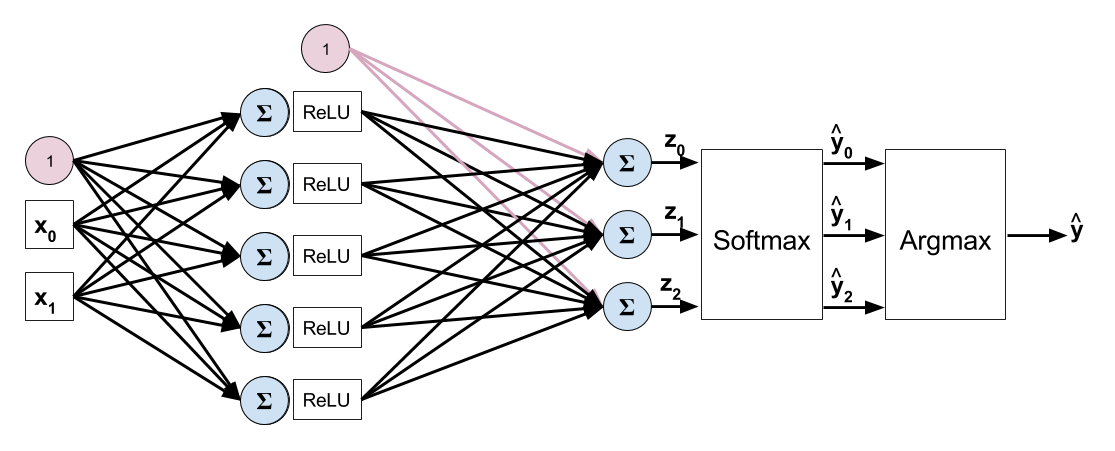

O modelo deste notebook, o mesmo do slide "Perceptron multicamadas (MLP)", tem **duas** camadas escondidas de 5 neurônios. As setas indicam o sentido do cálculo da previsão (forward). Cada camada `nn.Linear(n_in, n_out)` tem $n_{in} \times n_{out}$ pesos e $n_{out}$ bias:

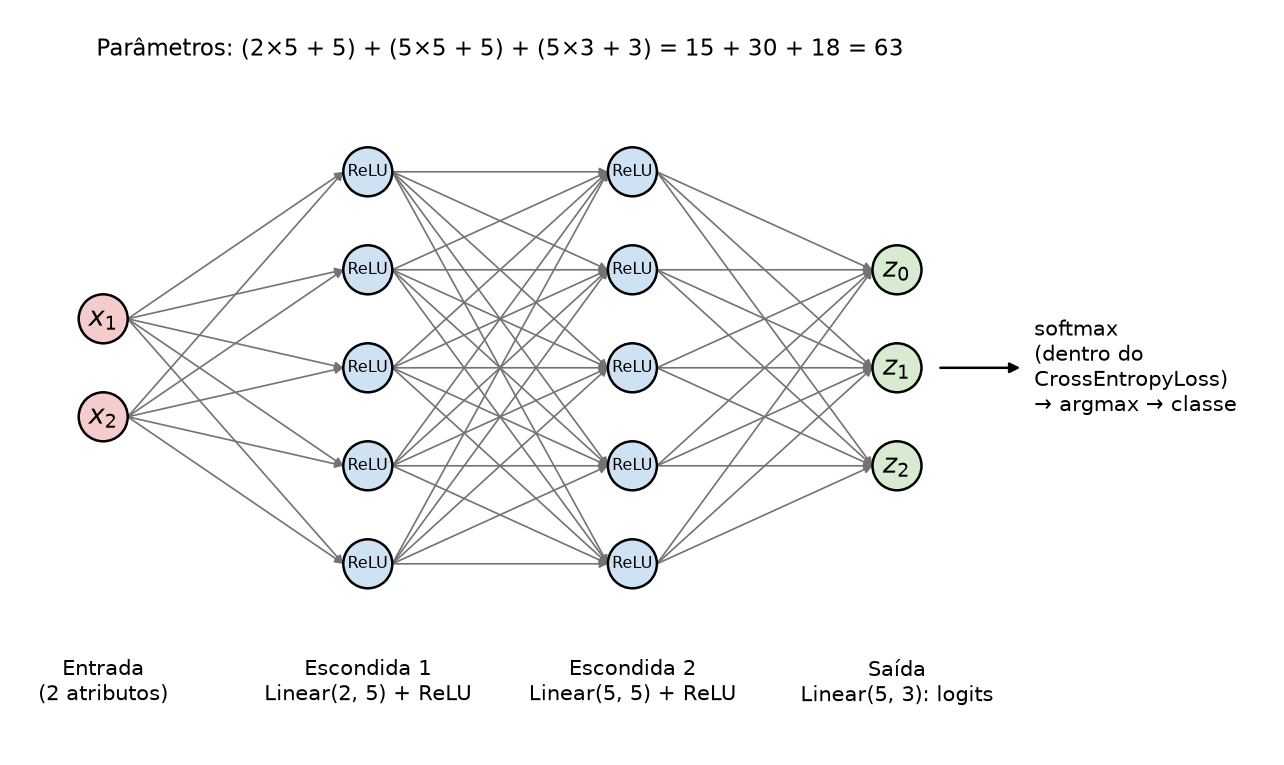

A saída da última camada são os **logits** $z_0, z_1, z_2$ (valores reais, não probabilidades). A softmax, que transforma logits em probabilidades, já está dentro do `nn.CrossEntropyLoss`; para prever a classe, basta pegar o maior logit (argmax).

## Importação das bibliotecas

In [ ]:
from sklearn import datasets
from IPython import display
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import pandas as pd

import torch
import torch.nn as nn

torch.manual_seed(0)  # semente fixa: mesma inicialização dos pesos a cada execução
np.random.seed(0)

colors = np.array(['r', 'y', 'b'])                              # cor de cada classe nos pontos
region_cmap = ListedColormap(['#ffc9c9', '#fff3b0', '#c6d8ff'])  # mesmas cores, claras, nas regiões

## Leitura, normalização e visualização dos dados

Usamos os mesmos dois atributos do 3.1: comprimento da sépala (coluna 0) e comprimento da pétala (coluna 2). Cada atributo é normalizado para o intervalo $[0, 1]$ (subtrai o mínimo e divide pela amplitude).

Para os experimentos, troque `option` para `'moon'`, `'circles'` ou `'blobs'` e rode o notebook de novo.

In [ ]:
n_samples = 150
options = ['iris', 'moon', 'circles', 'blobs']
option = options[0]
if option == 'iris':
    iris = datasets.load_iris()
    X = iris.data[:, ::2]  # comprimento da sépala e da pétala, índices 0 e 2
    Xc = X - X.min(axis=0)
    Xc /= Xc.max(axis=0)
    Y = iris.target
    feature_names = ['Comprimento da sépala (normalizado)', 'Comprimento da pétala (normalizado)']
else:
    if option == 'moon':
        Xc, Y = datasets.make_moons(n_samples=n_samples, noise=.15, random_state=0)
    elif option == 'circles':
        Xc, Y = datasets.make_circles(n_samples=n_samples, factor=.5, noise=.1, random_state=0)
    elif option == 'blobs':
        Xc, Y = datasets.make_blobs(n_samples=n_samples, centers=3, cluster_std=1.2, random_state=0)
    feature_names = ['$x_1$', '$x_2$']

print('Xc:', Xc.shape, ' Y:', Y.shape, ' classes:', np.unique(Y))
plt.scatter(Xc[:, 0], Xc[:, 1], c=colors[Y])
plt.xlabel(feature_names[0])
plt.ylabel(feature_names[1])
plt.show()

### Prepara os dados para o PyTorch

A entrada vira um tensor `float32`, shape (150, 2); os rótulos viram um tensor de inteiros (`long`), shape (150,), que é o formato que o `nn.CrossEntropyLoss` espera para a classe correta.

In [ ]:
X_tensor = torch.tensor(Xc, dtype=torch.float32)
Y_tensor = torch.tensor(Y, dtype=torch.long)
print(X_tensor.shape, X_tensor.dtype, Y_tensor.shape, Y_tensor.dtype)

## Construindo o modelo da rede

`nn.Sequential` encadeia módulos: a saída de um é a entrada do próximo. Aqui: `Linear(2, 5)` → `ReLU` → `Linear(5, 5)` → `ReLU` → `Linear(5, 3)`. A ReLU não tem parâmetros. A última camada não tem ativação, porque produz os logits que vão para o `nn.CrossEntropyLoss`.

A classe `Modelo` só guarda o `nn.Sequential` e o chama no `forward`; o slide usa diretamente `model = nn.Sequential(...)`, que é equivalente.

In [ ]:
class Modelo(nn.Module):
    def __init__(self):
        super().__init__()
        self.dense = nn.Sequential(
            nn.Linear(2, 5),    # entrada → escondida 1
            nn.ReLU(),
            nn.Linear(5, 5),    # escondida 1 → escondida 2
            nn.ReLU(),
            nn.Linear(5, 3),    # escondida 2 → 3 classes (logits)
        )

    def forward(self, x):
        x = self.dense(x)
        return x

model = Modelo()
print(model)
print('Número de parâmetros:', sum(p.numel() for p in model.parameters()))  # (2*5+5) + (5*5+5) + (5*3+3) = 63

## Função `predict`: previsão de classes

Usada na avaliação e para desenhar a fronteira de decisão. `model.eval()` coloca o modelo em modo de avaliação e `torch.no_grad()` desliga o registro do gradiente, que não é necessário para prever. `torch.argmax(outputs, dim=1)` devolve, para cada amostra, o índice do maior logit, isto é, a classe prevista.

In [ ]:
def predict(model, inputs):
    model.eval()
    with torch.no_grad():
        outputs = model(inputs)                  # logits, shape (N, 3)
        predicts = torch.argmax(outputs, dim=1)  # classe prevista, shape (N,)
    return predicts.numpy()

## Classe para visualização dinâmica

A cada 250 épocas, `BoundaryPlotter` redesenha dois gráficos: à esquerda, a curva da função de custo (loss); à direita, a classe prevista para cada ponto de uma grade fina sobre o plano dos dois atributos (as regiões, com a cor clara da classe prevista). As linhas onde a cor muda são as fronteiras de decisão. `display.clear_output(wait=True)` apaga a figura anterior antes de mostrar a nova, o que produz a animação.

In [ ]:
class BoundaryPlotter():
    def __init__(self, model, X, Y, n_epochs, feature_names, h=.01, every=250):
        self.model = model
        self.X = X
        self.Y = Y
        self.n_epochs = n_epochs
        self.every = every
        x_min, x_max = X[:, 0].min() - .1, X[:, 0].max() + .1
        y_min, y_max = X[:, 1].min() - .1, X[:, 1].max() + .1
        self.xx, self.yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
        self.X_grid = torch.tensor(np.c_[self.xx.ravel(), self.yy.ravel()], dtype=torch.float32)
        self.loss_hist = []

        # Gráficos atualizados ao longo do treino
        self.fig = plt.figure(figsize=(10, 4.5), dpi=100)
        self.ax1 = self.fig.add_subplot(1, 2, 1)
        self.ax2 = self.fig.add_subplot(1, 2, 2)
        self.feature_names = feature_names

    def on_epoch_end(self, epoch, loss):
        self.loss_hist.append(loss)
        if epoch % self.every == 0 or epoch == self.n_epochs - 1:
            self.ax1.clear()
            self.ax1.plot(np.arange(epoch + 1), self.loss_hist, 'b', linewidth=2.0)
            self.ax1.set_xlim(0, self.n_epochs)
            self.ax1.set_xlabel('Época')
            self.ax1.set_ylabel('Custo (cross-entropy)')
            self.ax1.set_title(f'Época {epoch + 1}: custo = {loss:.4f}')
            self.ax1.grid(True)

            Z = predict(self.model, self.X_grid).reshape(self.xx.shape)
            self.ax2.clear()
            self.ax2.pcolormesh(self.xx, self.yy, Z, cmap=region_cmap, vmin=0, vmax=2, shading='auto')
            self.ax2.scatter(self.X[:, 0], self.X[:, 1], s=40, c=colors[self.Y], edgecolors='k')
            self.ax2.set_xlabel(self.feature_names[0])
            self.ax2.set_ylabel(self.feature_names[1])
            self.ax2.set_title('Fronteira de decisão')
            self.fig.tight_layout()

            display.clear_output(wait=True)
            display.display(self.fig)

    def on_train_end(self):
        plt.close(self.fig)  # evita que a figura seja mostrada de novo no fim da célula

## Treinamento

- Taxa de aprendizado (learning rate) `lr = 0.15` e gradiente descendente com `torch.optim.SGD` (visto no 2.5).
- Função de custo `nn.CrossEntropyLoss` (vista no 3.1): recebe os logits e o rótulo correto e aplica log-softmax internamente. Por isso não aplicamos softmax na saída do modelo.
- `batch_size = 150` é o tamanho do conjunto inteiro: cada época usa todas as amostras de uma vez, ou seja, cada época é **uma** iteração de gradiente descendente (não há mini-batches aqui).

In [ ]:
lr = 0.15

optimizer = torch.optim.SGD(model.parameters(), lr=lr)

criterion = nn.CrossEntropyLoss()

### Laço principal de treinamento

A cada época: previsão (forward) → custo → `optimizer.zero_grad()` (zera os gradientes acumulados) → `loss.backward()` (retropropagação: calcula os gradientes) → `optimizer.step()` (atualiza os pesos). `loss.item()` converte o custo, um tensor de um elemento, em número Python, para guardá-lo na lista `losses` sem manter o grafo de gradientes.

In [ ]:
batch_size = 150   # = número de amostras: gradiente descendente com o conjunto inteiro
n_epochs = 3000

# Definindo o plotter
boundary_plot = BoundaryPlotter(model, Xc, Y, n_epochs, feature_names)

losses = []
for i in range(n_epochs):
    model.train()
    # previsão da rede (logits)
    output = model(X_tensor)

    loss = criterion(output, Y_tensor)

    # zera os gradientes, retropropagação, atualização dos parâmetros (gradiente descendente)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    losses.append(loss.item())
    boundary_plot.on_epoch_end(i, loss.item())

boundary_plot.on_train_end()
print('Custo final:', losses[-1])

## Avaliação

### Imprimindo os pesos finais

`model.state_dict()` é um dicionário com todos os parâmetros do modelo (nome → tensor). Os nomes `dense.0`, `dense.2` e `dense.4` são as posições das camadas `nn.Linear` dentro do `nn.Sequential` (as posições 1 e 3 são as ReLU, sem parâmetros).

In [ ]:
for name, w in model.state_dict().items():
    print('{:16}{}'.format(name, tuple(w.size())))
    print(w)

### Avaliação do classificador

A acurácia abaixo é medida nos **mesmos dados usados no treino**, como no 3.1. Ela mostra o quanto o modelo se ajustou a esses dados, não o quanto ele acerta em flores novas. Essa diferença é o assunto do 4.3.

In [ ]:
Y_hat = predict(model, X_tensor)
accuracy = (Y_hat == Y).mean()
print('Acurácia no treino:', accuracy)

### Matriz de confusão

Linhas: classe prevista; colunas: classe correta. Os valores fora da diagonal são os erros.

In [ ]:
pd.crosstab(pd.Series(Y_hat, name='prevista'), pd.Series(Y, name='correta'))

## Exercícios

As funções abaixo treinam uma rede sem animação e desenham a fronteira de decisão final. Elas são usadas nos exercícios. `compare` recebe um dicionário `{título: (camadas escondidas, ativação)}`, treina cada rede com a mesma semente, `lr` e número de épocas, e mostra as fronteiras lado a lado. `make_mlp([5, 5])` cria a mesma rede 2-5-5-3 deste notebook; `make_mlp([20])` cria uma rede com uma camada escondida de 20 neurônios; `make_mlp([])` cria um modelo sem camada escondida (a regressão softmax do 3.1).

In [ ]:
def make_mlp(hidden, activation=nn.ReLU, n_in=2, n_out=3):
    '''Cria um nn.Sequential com as camadas escondidas da lista `hidden` (neurônios por camada).
    `activation=None` cria a rede sem ativação entre as camadas.'''
    layers, n = [], n_in
    for h in hidden:
        layers.append(nn.Linear(n, h))
        if activation is not None:
            layers.append(activation())
        n = h
    layers.append(nn.Linear(n, n_out))
    return nn.Sequential(*layers)


def train_mlp(model, X, Y, n_epochs=3000, lr=0.15):
    '''Treina com SGD e o conjunto inteiro (como acima). Devolve o custo final e a acurácia no treino.'''
    Xt = torch.tensor(X, dtype=torch.float32)
    Yt = torch.tensor(Y, dtype=torch.long)
    opt = torch.optim.SGD(model.parameters(), lr=lr)
    crit = nn.CrossEntropyLoss()
    model.train()
    for _ in range(n_epochs):
        loss = crit(model(Xt), Yt)
        opt.zero_grad()
        loss.backward()
        opt.step()
    acc = (predict(model, Xt) == Y).mean()
    return loss.item(), acc


def plot_boundary(ax, model, X, Y, title, h=.01):
    x_min, x_max = X[:, 0].min() - .1, X[:, 0].max() + .1
    y_min, y_max = X[:, 1].min() - .1, X[:, 1].max() + .1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
    Z = predict(model, torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)).reshape(xx.shape)
    ax.pcolormesh(xx, yy, Z, cmap=region_cmap, vmin=0, vmax=2, shading='auto')
    ax.scatter(X[:, 0], X[:, 1], s=20, c=colors[Y], edgecolors='k')
    ax.set_title(title, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])


def compare(configs, X, Y, n_epochs=3000, lr=0.15, seed=0):
    '''configs: dicionário {título: (lista de neurônios por camada escondida, ativação)}.
    Cria e treina cada rede (com a mesma semente) e desenha as fronteiras lado a lado.'''
    n_cols = 3
    n_rows = (len(configs) + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3.8 * n_rows), squeeze=False)
    for ax, (title, (hidden, activation)) in zip(axes.ravel(), configs.items()):
        torch.manual_seed(seed)
        m = make_mlp(hidden, activation)
        loss, acc = train_mlp(m, X, Y, n_epochs, lr)
        n_par = sum(p.numel() for p in m.parameters())
        print(f'{title:28s} parâmetros={n_par:5d}  custo={loss:.4f}  acurácia={acc:.3f}')
        plot_boundary(ax, m, X, Y, f'{title}\n{n_par} parâm., acc={acc:.2f}')
    for ax in axes.ravel()[len(configs):]:
        ax.axis('off')
    fig.tight_layout()
    plt.show()

**1.** Altere o número de neurônios e de camadas da rede. Compare pelo menos cinco arquiteturas no Iris (por exemplo: sem camada escondida, uma camada com 2, 5 e 50 neurônios, duas camadas 5-5 e três camadas 20-20-20), mantendo `lr` e `n_epochs`. Depois repita com os dados `moon` (`datasets.make_moons(n_samples=150, noise=.15, random_state=0)`). Escreva suas conclusões: o que muda na fronteira, no custo final e na acurácia de treino?

In [ ]:
# meias-luas, usadas também nos exercícios 2 e 3
X_moon, Y_moon = datasets.make_moons(n_samples=150, noise=.15, random_state=0)

# TODO: escreva sua solução aqui


*Escreva sua resposta aqui.*

**2.** No lugar da ReLU, use a sigmoide (`nn.Sigmoid`) na rede 5-5, com o mesmo `lr` e o mesmo número de épocas. Compare com a ReLU no Iris e nas meias-luas. O que aconteceu? Descreva, usando o que viu no 4.1 sobre a derivada da sigmoide. Teste também a sigmoide com uma taxa de aprendizado 10 vezes maior (`lr=1.5` em `train_mlp`).

In [ ]:
# TODO: escreva sua solução aqui


*Escreva sua resposta aqui.*

**3.** O que ocorre quando não se utiliza ativação não linear entre as camadas? Treine a rede 5-5 sem ativação (ativação `None` em `compare`) e compare com o modelo sem camada escondida e com a rede 5-5 com ReLU, no Iris e nas meias-luas.

In [ ]:
# TODO: escreva sua solução aqui


*Escreva sua resposta aqui.*

## Aprendizados

- Uma rede com camadas escondidas e ativação não linear (ReLU) desenha fronteiras de decisão curvas; sem a ativação, ela volta a ser um modelo linear, como a regressão softmax do 3.1.
- A rede 2-5-5-3 tem 63 parâmetros: cada `nn.Linear(n_in, n_out)` tem $n_{in} \times n_{out}$ pesos e $n_{out}$ bias.
- O laço de treino é o mesmo dos notebooks anteriores (forward → custo → `zero_grad` → `backward` → `step`); só o modelo mudou.
- Mais neurônios e camadas reduzem o custo de treino, mas a acurácia no treino não diz como o modelo se sai em dados novos (4.3).

## Referências

- [PyTorch: nn.Sequential](https://docs.pytorch.org/docs/stable/generated/torch.nn.Sequential.html)
- [PyTorch: nn.CrossEntropyLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html)
- [scikit-learn: load_iris](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html)